In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

from sklearn.metrics import (
    accuracy_score, classification_report, roc_curve, roc_auc_score,
    mean_absolute_error, mean_squared_error, r2_score,
    confusion_matrix, f1_score, average_precision_score,
    mean_absolute_percentage_error
)

from sklearn.preprocessing import (
    LabelEncoder, StandardScaler, OneHotEncoder, OrdinalEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (
    train_test_split, cross_val_score, KFold,
    StratifiedKFold, RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier,
    ExtraTreesClassifier, RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')

RANDOM_STATE = 42

# 1) Data Loading

In [2]:
df=pd.read_csv('stay_listings.csv')

In [3]:
print("We have {} Rows and {} Columns in our data".format(df.shape[0], df.shape[1]))

We have 10000 Rows and 21 Columns in our data


In [4]:
df.head(5)

,listing_id,city,property_type,bedrooms,bathrooms,guest_capacity,distance_center_km,price_per_night_usd,cleaning_fee_usd,superhost,...,host_years,photo_count,amenities_count,instant_book,min_nights,review_score,reviews_count,occupancy_rate_pct,annual_revenue_usd,high_demand
0,L00001,Mexico City,Entire home,2,1.5,5,7.1,52.0,17.0,1,...,6.9,27,23,0,30,4.59,3,61.3,11500.0,0
1,L00002,Paris,Entire home,1,1.0,3,4.6,147.0,52.0,0,...,1.4,13,20,1,7,4.61,7,23.7,11300.0,0
2,L00003,New York,Entire home,2,2.0,5,1.6,131.0,36.0,0,...,5.1,18,35,0,30,4.64,6,45.8,21700.0,0
3,L00004,Tokyo,Entire home,2,1.5,5,5.7,164.0,68.0,0,...,3.6,36,43,0,2,4.71,20,42.6,25300.0,0
4,L00005,Berlin,Entire home,3,2.0,8,4.6,321.0,32.0,1,...,5.6,27,48,1,5,4.98,28,65.1,74500.0,0


In [5]:
df.columns

Index(['listing_id', 'city', 'property_type', 'bedrooms', 'bathrooms',
       'guest_capacity', 'distance_center_km', 'price_per_night_usd',
       'cleaning_fee_usd', 'superhost', 'host_response_rate', 'host_years',
       'photo_count', 'amenities_count', 'instant_book', 'min_nights',
       'review_score', 'reviews_count', 'occupancy_rate_pct',
       'annual_revenue_usd', 'high_demand'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   listing_id           10000 non-null  object 
 1   city                 10000 non-null  object 
 2   property_type        10000 non-null  object 
 3   bedrooms             10000 non-null  int64  
 4   bathrooms            10000 non-null  float64
 5   guest_capacity       10000 non-null  int64  
 6   distance_center_km   10000 non-null  float64
 7   price_per_night_usd  10000 non-null  float64
 8   cleaning_fee_usd     10000 non-null  float64
 9   superhost            10000 non-null  int64  
 10  host_response_rate   10000 non-null  float64
 11  host_years           10000 non-null  float64
 12  photo_count          10000 non-null  int64  
 13  amenities_count      10000 non-null  int64  
 14  instant_book         10000 non-null  int64  
 15  min_nights           10000 non-null  

In [7]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
listing_id,10000,10000,L00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,10000,12,New York,1237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
property_type,10000,4,Entire home,5895,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bedrooms,10000.0,NaN,NaN,NaN,1.4066,0.936143,0.0,1.0,1.0,2.0,4.0
bathrooms,10000.0,NaN,NaN,NaN,1.5638,0.499354,0.5,1.0,1.5,2.0,3.5
guest_capacity,10000.0,NaN,NaN,NaN,4.3275,1.942375,1.0,3.0,4.0,5.0,10.0
distance_center_km,10000.0,NaN,NaN,NaN,4.10952,3.730051,0.2,1.8,3.0,5.1,30.0
price_per_night_usd,10000.0,NaN,NaN,NaN,91.6663,45.596351,18.0,59.0,82.0,114.0,414.0
cleaning_fee_usd,10000.0,NaN,NaN,NaN,27.4876,18.061541,2.0,15.0,23.0,36.0,164.0
superhost,10000.0,NaN,NaN,NaN,0.3617,0.480517,0.0,0.0,0.0,1.0,1.0


In [8]:
# check the missing values
df.isnull().sum()

listing_id             0
city                   0
property_type          0
bedrooms               0
bathrooms              0
guest_capacity         0
distance_center_km     0
price_per_night_usd    0
cleaning_fee_usd       0
superhost              0
host_response_rate     0
host_years             0
photo_count            0
amenities_count        0
instant_book           0
min_nights             0
review_score           0
reviews_count          0
occupancy_rate_pct     0
annual_revenue_usd     0
high_demand            0
dtype: int64

In [9]:
# check the duplicate values
df.duplicated().sum()

0

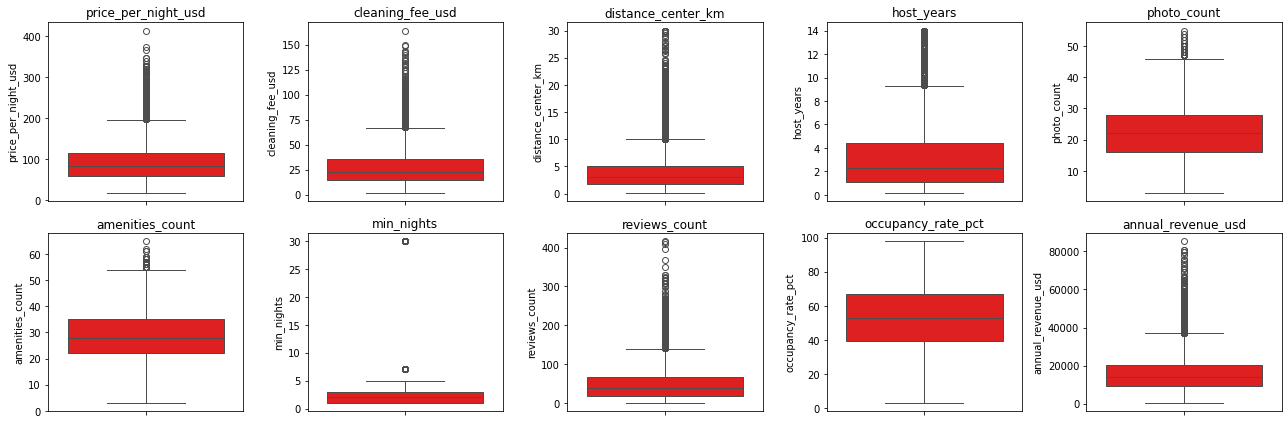

In [10]:
# check for the outliers

num = ['price_per_night_usd', 'cleaning_fee_usd', 'distance_center_km', 'host_years', 'photo_count',
       'amenities_count', 'min_nights', 'reviews_count', 'occupancy_rate_pct', 'annual_revenue_usd']


fig, axes=plt.subplots(2,5,figsize=(18,6))

for ax,col in zip(axes.ravel(),num):
    sns.boxplot(y=df[col],ax=ax,color='red')
    ax.set_title(col)
    
plt.tight_layout()
plt.show()

# 2) EDA- Exploratory Data Analysis

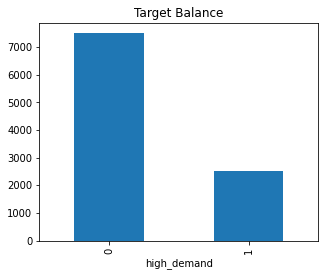

In [11]:
# Target Balance

plt.figure(figsize=(5,4))
df['high_demand'].value_counts().plot(kind='bar')
plt.title('Target Balance')
plt.show()

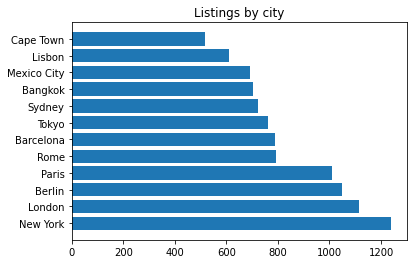

In [12]:
# Listing based on cities

plt.figure(figsize=(6,4))
plt.barh(df['city'].value_counts().index,df['city'].value_counts().values)
plt.title('Listings by city')
plt.show()

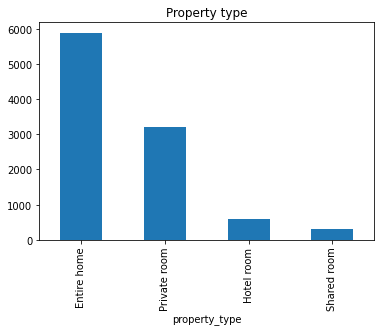

In [13]:
# Property Type

plt.figure(figsize=(6,4))
df['property_type'].value_counts().plot(kind='bar')
plt.title('Property type')
plt.show()

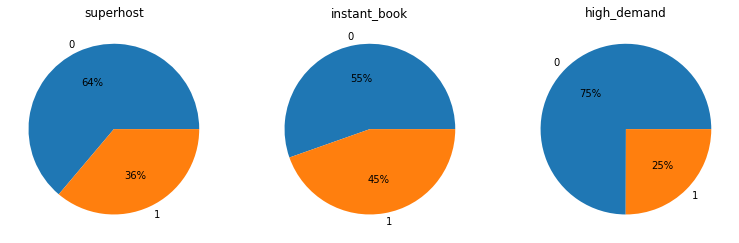

In [14]:
# Pie charts of the binary flags
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ['superhost', 'instant_book', 'high_demand']):
    df[col].value_counts().plot.pie(ax=ax, autopct='%1.0f%%', title=col, ylabel='')
plt.show()

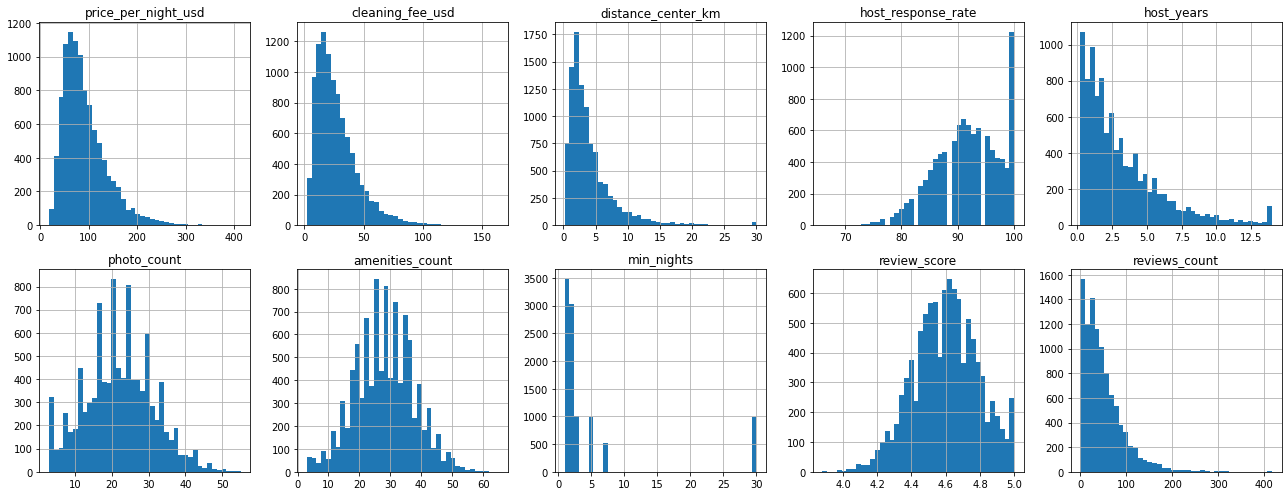

In [15]:
cols = ['price_per_night_usd', 'cleaning_fee_usd', 'distance_center_km', 'host_response_rate', 'host_years',
        'photo_count', 'amenities_count', 'min_nights', 'review_score', 'reviews_count']
df[cols].hist(bins=40,figsize=(18,7),layout=(2,5))
plt.tight_layout()
plt.show()

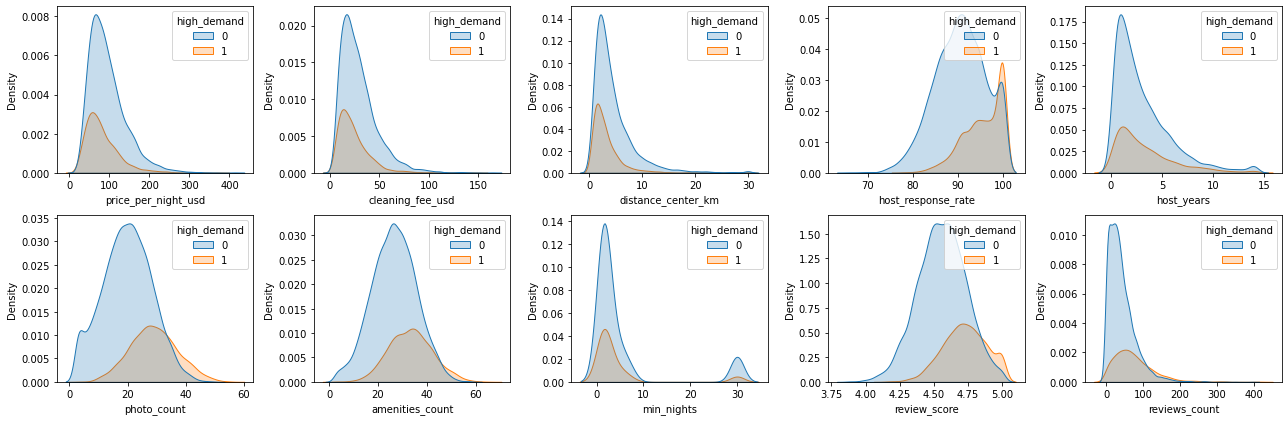

In [16]:
fig,axes=plt.subplots(2,5,figsize=(18,6))

for ax,col in zip(axes.flat,cols):
    sns.kdeplot(data=df,x=col,hue='high_demand',fill=True,ax=ax)
    
plt.tight_layout()
plt.show()

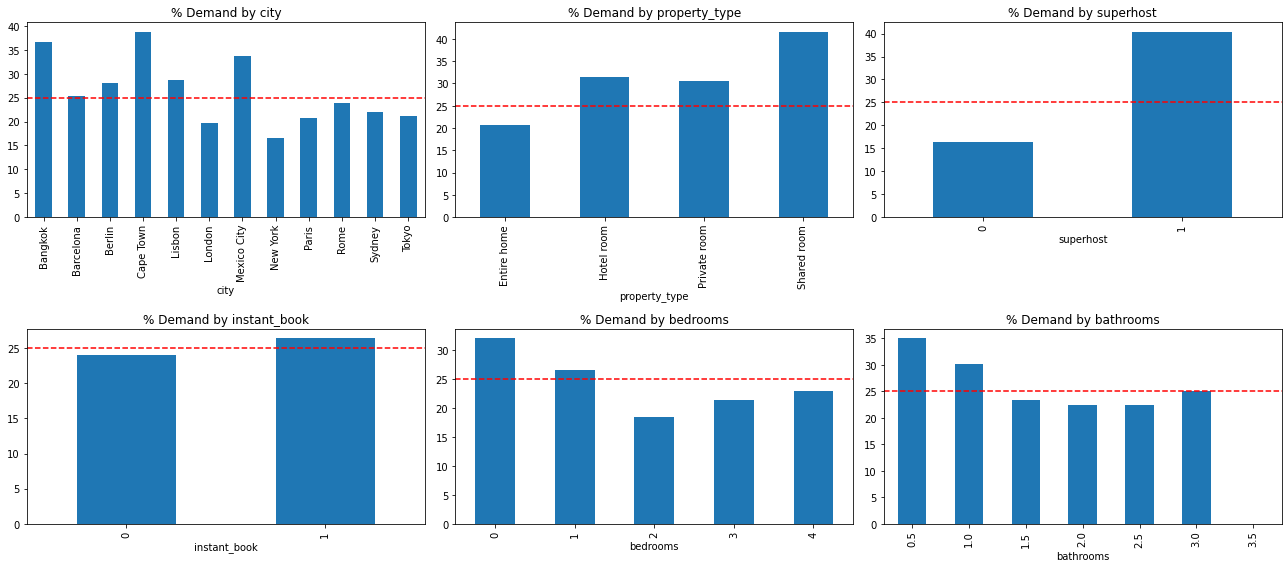

In [17]:
cols = ['city', 'property_type', 'superhost', 'instant_book', 'bedrooms', 'bathrooms']

fig,axes=plt.subplots(2,3,figsize=(18,8))

for ax,col in zip(axes.flat,cols):
    (df.groupby(col)['high_demand'].mean()*100).plot.bar(ax=ax,title=f'% Demand by {col}')
    ax.axhline(25,color='red', ls='--')

plt.tight_layout()
plt.show()

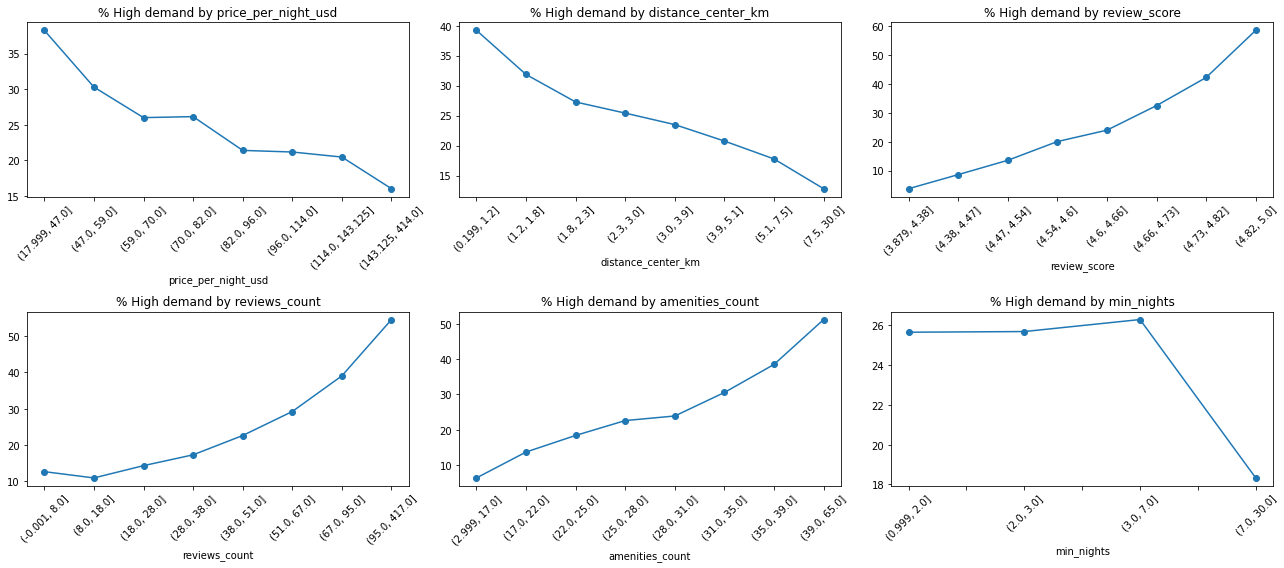

In [18]:
cols = ['price_per_night_usd', 'distance_center_km', 'review_score','reviews_count', 'amenities_count', 'min_nights']

fig,axes=plt.subplots(2,3,figsize=(18,8))

for ax,col in zip(axes.ravel(),cols):
    bins=pd.qcut(df[col],8,duplicates='drop')
    (df.groupby(bins)['high_demand'].mean()*100).plot(ax=ax,marker='o',title=f'% High demand by {col}')
    ax.tick_params(axis='x',rotation=45)
    
plt.tight_layout()
plt.show()

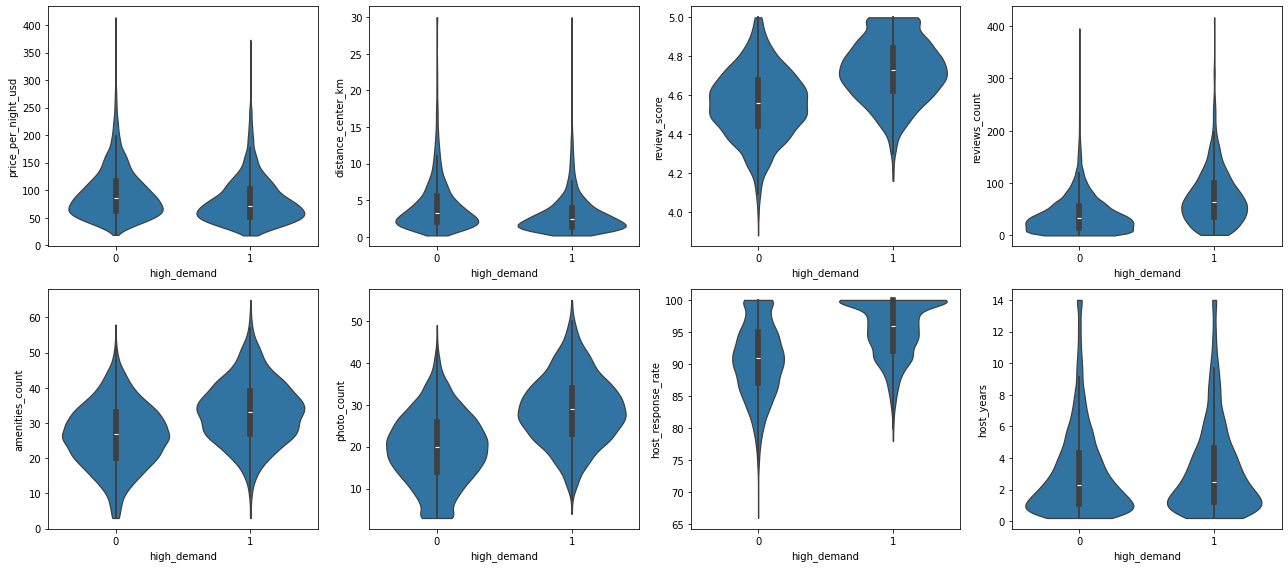

In [19]:
cols = ['price_per_night_usd', 'distance_center_km', 'review_score','reviews_count', 'amenities_count', 'photo_count',
        'host_response_rate', 'host_years']

fig,axes=plt.subplots(2,4,figsize=(18,8))

for ax,col in zip(axes.ravel(),cols):
    sns.violinplot(data=df,x='high_demand',y=col,ax=ax,cut=0)
    
plt.tight_layout()
plt.show()

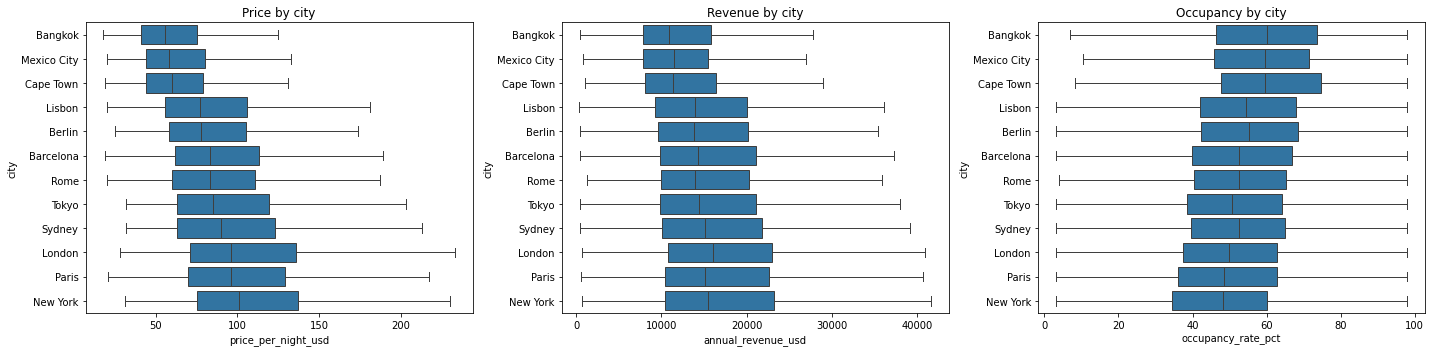

In [20]:
fig,axes=plt.subplots(1,3,figsize=(20,5))

order=df.groupby('city')['price_per_night_usd'].median().sort_values().index

for ax,col,title in zip(axes,['price_per_night_usd', 'annual_revenue_usd', 'occupancy_rate_pct'],
                        ['Price', 'Revenue', 'Occupancy']):
    
    sns.boxplot(data=df,x=col,y='city',order=order,ax=ax,showfliers=False)
    ax.set_title(f'{title} by city')
    
plt.tight_layout()
plt.show()

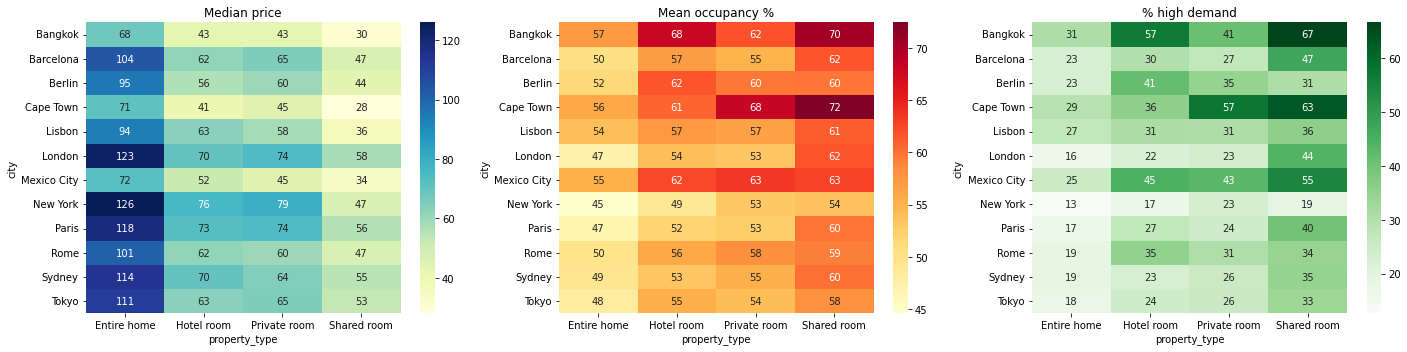

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, col, agg, title, cmap in zip(
    axes,
    ['price_per_night_usd', 'occupancy_rate_pct', 'high_demand'],
    ['median', 'mean', 'mean'],
    ['Median price', 'Mean occupancy %', '% high demand'],
    ['YlGnBu', 'YlOrRd', 'Greens']
):
    data = df.pivot_table(index='city', columns='property_type',
                          values=col, aggfunc=agg)

    if col == 'high_demand':
        data *= 100

    sns.heatmap(data, annot=True, fmt='.0f', cmap=cmap, ax=ax)
    ax.set_title(title)

plt.tight_layout()
plt.show()

In [22]:
df.groupby('city').agg(
    listings=('listing_id', 'count'),
    avg_price=('price_per_night_usd', 'mean'),
    avg_occupancy=('occupancy_rate_pct', 'mean'),
    avg_revenue=('annual_revenue_usd', 'mean'),
    pct_high_demand=('high_demand', 'mean')
).round(2).sort_values('avg_revenue', ascending=False)

,listings,avg_price,avg_occupancy,avg_revenue,pct_high_demand
city,,,,,
London,1114,108.28,50.06,18352.69,0.20
New York,1237,112.49,47.87,17984.32,0.17
Paris,1009,105.42,49.42,17397.13,0.21
Sydney,723,98.86,51.94,17271.65,0.22
Tokyo,763,95.85,50.90,16477.72,0.21
Barcelona,788,91.38,52.60,16224.87,0.25
Lisbon,612,85.78,55.08,16042.81,0.29
Rome,794,90.18,53.03,16032.24,0.24
Berlin,1047,85.15,54.97,15655.40,0.28


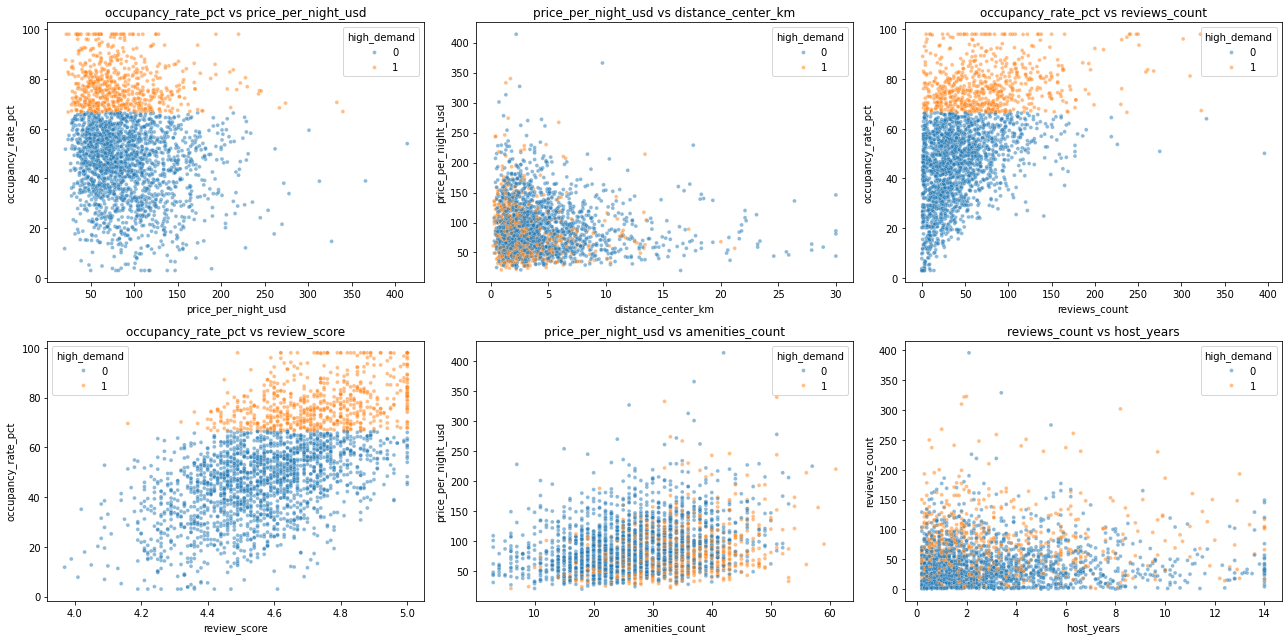

In [23]:
pairs = [('price_per_night_usd', 'occupancy_rate_pct'),('distance_center_km', 'price_per_night_usd'),
         ('reviews_count', 'occupancy_rate_pct'),('review_score', 'occupancy_rate_pct'),
         ('amenities_count', 'price_per_night_usd'),('host_years', 'reviews_count')]

fig,axes=plt.subplots(2,3,figsize=(18,9))
sample=df.sample(2500,random_state=1)

for ax,(x,y)in zip(axes.ravel(),pairs):
    sns.scatterplot(data=sample,x=x,y=y,hue='high_demand',alpha=.5,s=15,ax=ax)
    ax.set_title(f'{y} vs {x}')
    
plt.tight_layout()
plt.show()

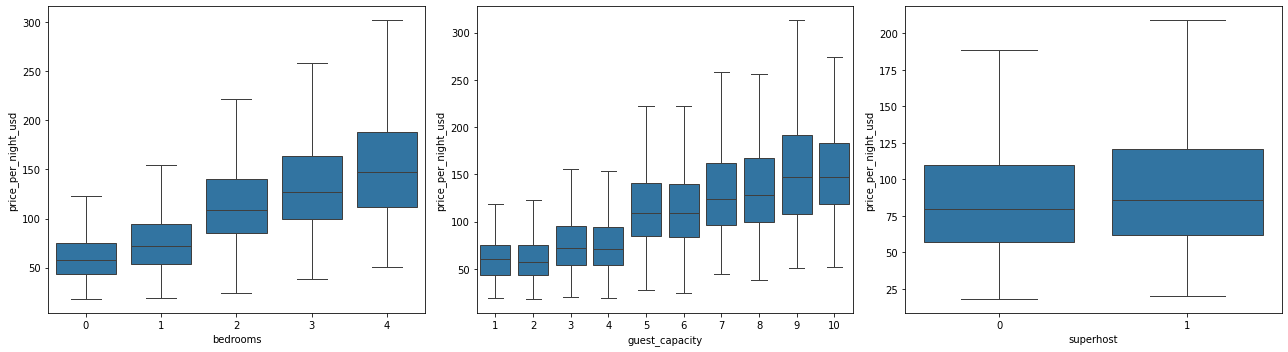

In [24]:
fig,axes=plt.subplots(1,3,figsize=(18,5))

for ax,col in zip(axes,['bedrooms', 'guest_capacity', 'superhost']):
    sns.boxplot(data=df,x=col,y='price_per_night_usd',ax=ax,showfliers=False)
    
plt.tight_layout()
plt.show()

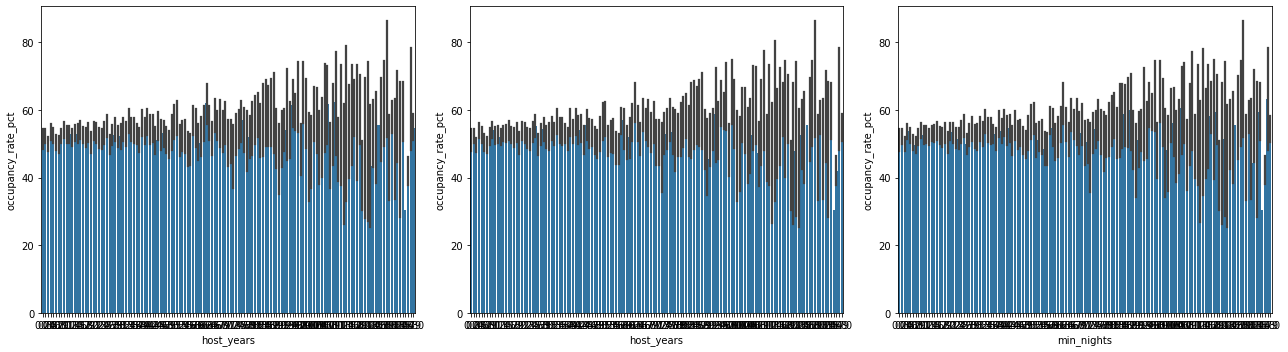

In [25]:
fig,axes=plt.subplots(1,3,figsize=(18,5))

for ax,col in zip(axes,['superhost', 'instant_book', 'min_nights']):
    
    sns.barplot(x=pd.cut(df[x], [0, 1, 2, 3, 7, 30]) if x == 'min_nights' else x,y='occupancy_rate_pct', data=df, ax=ax)
    
    axes[2].set_xlabel('min_nights')
    
plt.tight_layout()
plt.show()

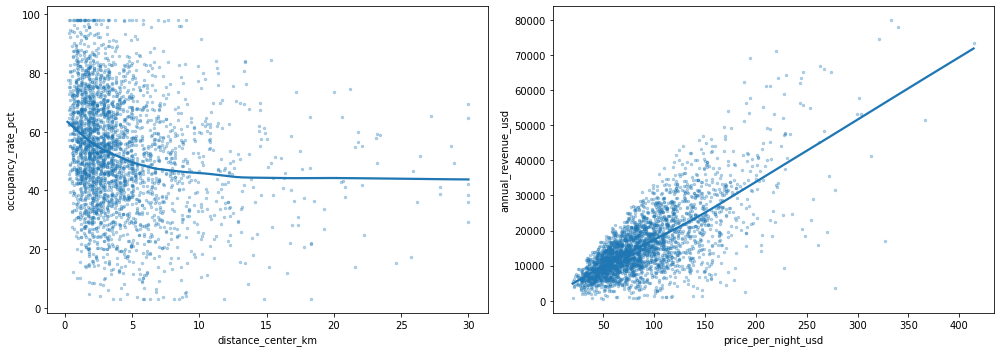

In [26]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
sample=df.sample(3000,random_state=1)

for ax,x,y in zip(axes,['distance_center_km', 'price_per_night_usd'],
                     ['occupancy_rate_pct', 'annual_revenue_usd']):
    sns.regplot(data=sample,x=x,y=y,lowess=True,scatter_kws={'s': 6, 'alpha': .3}, ax=ax)
    
plt.tight_layout()
plt.show()

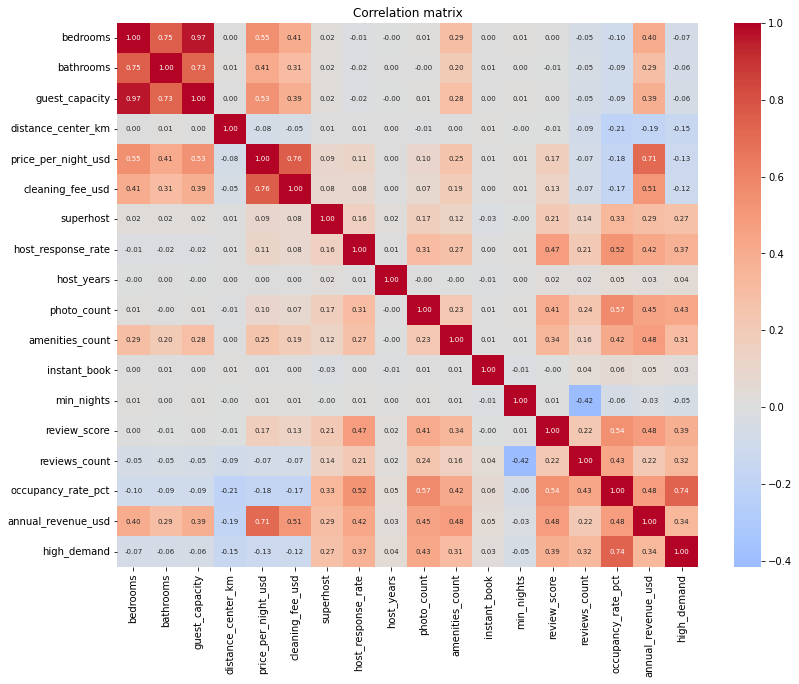

In [27]:
# corelation

corr = df.select_dtypes('number').corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Correlation matrix'); 
plt.show()

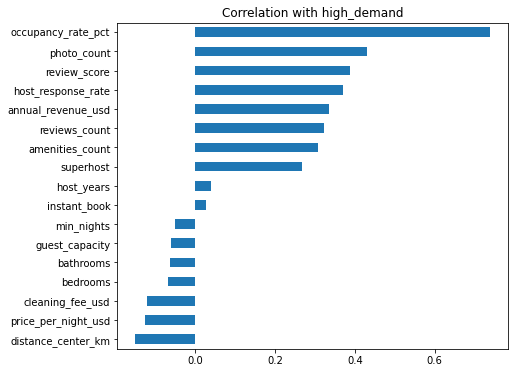

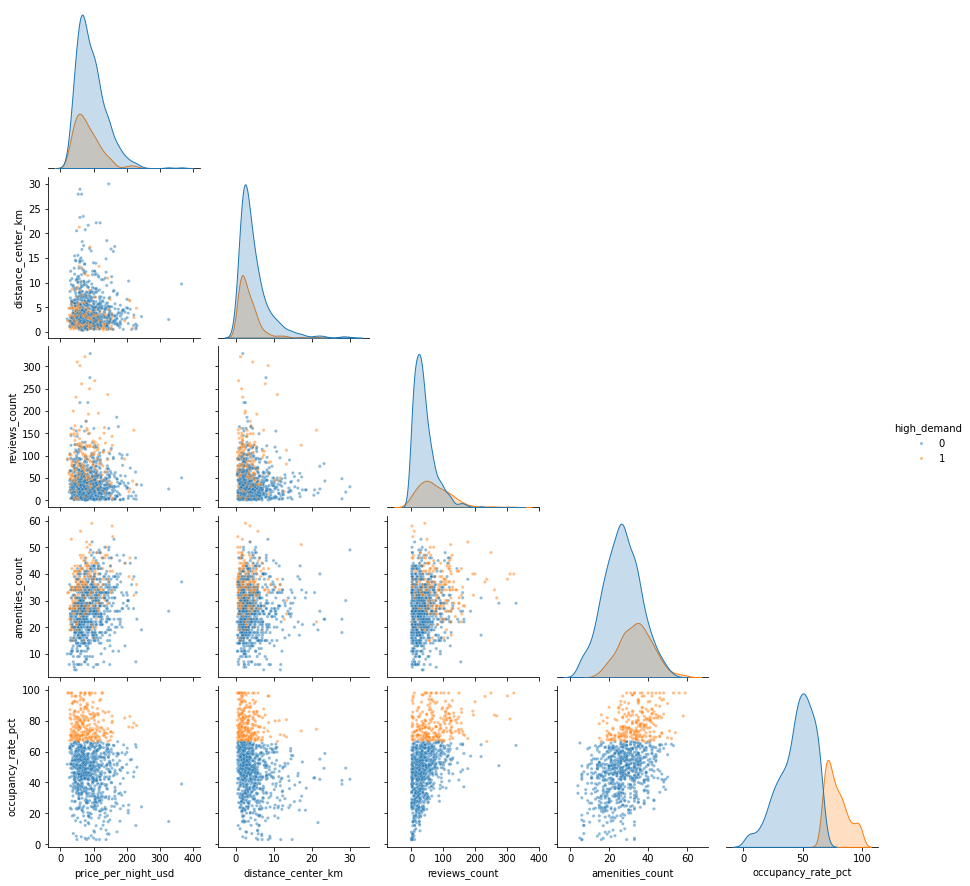

In [28]:
corr['high_demand'].drop('high_demand').sort_values().plot.barh(figsize=(7, 6), title='Correlation with high_demand')

plt.show()

sns.pairplot(df.sample(1000, random_state=1),
             vars=['price_per_night_usd', 'distance_center_km', 'reviews_count', 'amenities_count', 'occupancy_rate_pct'],
             hue='high_demand', plot_kws={'s': 10, 'alpha': .5}, corner=True)
plt.show()

# 3) Data Leakeage

In [29]:
print(df.groupby('high_demand')['occupancy_rate_pct'].agg(['min','max']))

ratio=df['annual_revenue_usd']/(df['price_per_night_usd']*365*df['occupancy_rate_pct']/100)

print('Revenue ratio:',ratio.mean().round(2))

leak=['occupancy_rate_pct', 'annual_revenue_usd']

              min   max
high_demand            
0             3.0  66.5
1            66.6  98.0
Revenue ratio: 0.94


# 4) Feature Engineering

In [30]:
def add_features(d):
    d = d.copy()
    d['price_per_guest'] = d['price_per_night_usd'] / d['guest_capacity']
    d['cleaning_ratio'] = d['cleaning_fee_usd'] / d['price_per_night_usd']
    d['reviews_per_year'] = d['reviews_count'] / d['host_years'].clip(lower=0.25)
    d['is_central'] = (d['distance_center_km'] <= 2).astype(int)
    d['long_stay_only'] = (d['min_nights'] >= 7).astype(int)
    d['log_price'] = np.log1p(d['price_per_night_usd'])
    d['log_reviews'] = np.log1p(d['reviews_count'])
    return d

y = df['high_demand']

X = add_features(df.drop(columns=['high_demand', 'listing_id'] + leak))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)

(8000, 24) (2000, 24)


# 5) Modelling

In [31]:
from xgboost import XGBClassifier

categorical_columns = ['city', 'property_type']
numerical_columns = [column for column in X.columns if column not in categorical_columns]

preprocessor = ColumnTransformer([('numerical', StandardScaler(), numerical_columns),
    ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_columns)])

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42, eval_metric='logloss')
}

model_scores = {name: cross_val_score(Pipeline([('preprocessor', preprocessor), ('model', model)]),
        X_train, y_train, cv=5, scoring='roc_auc').mean()
    for name, model in models.items()
}

pd.Series(model_scores, name='CV ROC-AUC').sort_values(ascending=False).round(4)

Logistic Regression    0.9419
XGBoost                0.9367
Gradient Boosting      0.9352
Random Forest          0.9283
Name: CV ROC-AUC, dtype: float64

In [32]:
from sklearn.model_selection import GridSearchCV

best_model_name = max(model_scores, key=model_scores.get)

parameter_grids = {
    'Logistic Regression': {'model__C': [0.1, 1, 10]},
    'Random Forest': {'model__max_depth': [8, 12, None], 'model__min_samples_leaf': [1, 5]},
    'Gradient Boosting': {'model__n_estimators': [150, 300], 'model__max_depth': [2, 3]},
    'XGBoost': {'model__max_depth': [3, 4, 6], 'model__learning_rate': [0.03, 0.1]}}

grid_search = GridSearchCV(Pipeline([('preprocessor', preprocessor), ('model', models[best_model_name])]),
    parameter_grids[best_model_name], cv=5, scoring='roc_auc', n_jobs=-1)

grid_search.fit(X_train, y_train)

print('Best model:', best_model_name)
print('Best parameters:', grid_search.best_params_)

best_model = grid_search.best_estimator_

Best model: Logistic Regression
Best parameters: {'model__C': 0.1}


ROC-AUC: 0.9478
              precision    recall  f1-score   support

           0       0.96      0.86      0.91      1499
           1       0.68      0.89      0.77       501

    accuracy                           0.87      2000
   macro avg       0.82      0.87      0.84      2000
weighted avg       0.89      0.87      0.87      2000



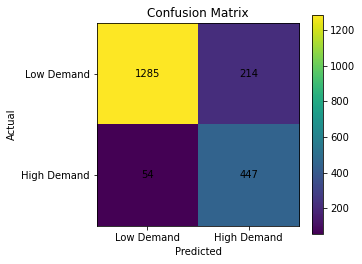

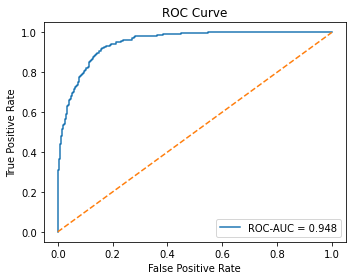

In [33]:
from sklearn.metrics import auc

predictions = best_model.predict(X_test)
probabilities = best_model.predict_proba(X_test)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 4))
print(classification_report(y_test, predictions))

# Confusion matrix
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(5, 4))
plt.imshow(cm, interpolation='nearest')
plt.title('Confusion Matrix')
plt.colorbar()

plt.xticks([0, 1], ['Low Demand', 'High Demand'])
plt.yticks([0, 1], ['Low Demand', 'High Demand'])
plt.xlabel('Predicted')
plt.ylabel('Actual')

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.tight_layout()
plt.show()

# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, probabilities)

plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f'ROC-AUC = {auc(fpr, tpr):.3f}')
plt.plot([0, 1], [0, 1], '--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.tight_layout()
plt.show()

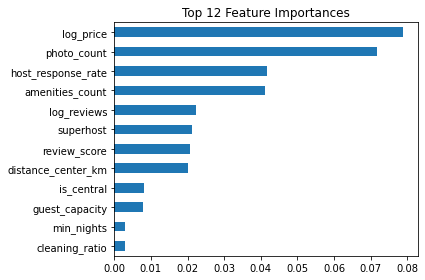

In [34]:
from sklearn.inspection import permutation_importance

feature_importance = permutation_importance(best_model, X_test, y_test,
    scoring='roc_auc', n_repeats=5, random_state=42)

pd.Series(feature_importance.importances_mean, index=X_test.columns) \
  .sort_values().tail(12).plot.barh(title='Top 12 Feature Importances')

plt.tight_layout()
plt.show()

# Thanks Please Upvote